# Challenge 1: E91 Quantum Key Distribution with an Eavesdropper

Author: Abdullah Al Omar Galib (Ahkatlio)

| Item | Details |
|:--|:--|
| Difficulty | Easy |
| Required knowledge | Qubits and Bloch sphere, single-qubit rotations, CNOT, measurement, Bell states, basic probability |
| Required packages | `qiskit` 2.6, `qiskit-aer` 0.18, `numpy`, `matplotlib` (see `requirements.txt`) |
| Total available points | 100 |
| Objective | Simulate a simplified E91 protocol, certify entanglement with the CHSH inequality, and detect an intercept-resend eavesdropper |
| Expected deliverables | Completed functions for Tasks E91-T1 to E91-T9, the experiments in Section 9, and written answers E91-Q1 to E91-Q4 |

## How to use this notebook

* Run the cells from top to bottom. The official grader re-executes the whole notebook in a clean kernel, so every result must be reproducible from a fresh start.
* Cells whose first line is `# Provided Code: Do Not Modify` are organizer-provided. Do not edit, delete, duplicate or reorder them. Changing protected code violates the competition rules (see Section 11) and is detected automatically.
* Cells whose first line is `# Participant Code: Task ...` are yours. Replace the line `# Your code here` and the `raise NotImplementedError(...)` statement with your implementation. Keep the function names and parameter lists exactly as given.
* You may add new cells anywhere (for exploration, plots or helper functions). Helper functions must be defined before they are used.
* Written answers go into the Markdown cells labelled **Your answer**.
* Hints are hidden in collapsible sections. Open them in order; each hint reveals more than the previous one. Using hints has no effect on your score.
* The public check cell after each task tests only basic properties. Passing it does not guarantee full marks: the official grader uses additional hidden tests with other inputs, angles and seeds.

## 1. Problem overview

Quantum key distribution (QKD) lets two parties, Alice and Bob, establish a shared secret key whose secrecy rests on the laws of physics rather than on computational assumptions. In the protocol proposed by Ekert in 1991 (E91), a source distributes entangled qubit pairs to Alice and Bob. Each of them measures their qubit along a randomly chosen direction. Rounds in which their directions coincide produce perfectly correlated bits, which become the key. The remaining rounds are used to test a Bell inequality: an eavesdropper who gains information by measuring the qubits in transit destroys the entanglement and reduces the observed violation.

In this challenge you will build a **simplified simulation** of E91 with Qiskit and Qiskit Aer, add an intercept-resend eavesdropper (Eve), and quantify how her attack changes the correlations and the key error rate. In the stretch task you will investigate whether interception can be told apart from ordinary depolarizing noise in the transmission line.

This notebook is a teaching simulation, not a secure QKD implementation. A real system also needs authenticated classical communication, finite-key parameter estimation, error correction and privacy amplification, and it must account for imperfect devices.

## 2. Learning objectives

After completing this challenge you should be able to:

1. Prepare a Bell state and measure a qubit along an arbitrary direction in the $x$-$z$ plane.
2. Estimate correlation functions from finite measurement records and quantify their statistical uncertainty.
3. Evaluate the CHSH parameter and explain the classical bound $S \le 2$ and the quantum bound $S \le 2\sqrt{2}$.
4. Implement basis sifting and compute the quantum bit error rate (QBER).
5. Model an intercept-resend attack with mid-circuit measurement and predict its effect analytically.
6. Distinguish what a Bell test certifies from what a complete security proof requires.

## 3. Prerequisites

* Dirac notation, tensor products and expectation values $\langle \psi \rvert O \lvert \psi \rangle$.
* The Pauli matrices $X$, $Y$, $Z$ and the rotation $R_y(\theta) = e^{-i\theta Y/2}$.
* Building circuits in Qiskit: `QuantumCircuit`, `h`, `cx`, `ry`, `measure`, `append`.
* Running circuits on `AerSimulator` and reading counts or per-shot memory.
* Mean, variance and standard error of a sample average.

## 4. Scientific background

### 4.1 Entanglement as a resource for key distribution

The Bell state
$$
\lvert \Phi^{+} \rangle = \frac{1}{\sqrt{2}}\left(\lvert 00 \rangle + \lvert 11 \rangle\right)
$$
has perfectly correlated outcomes whenever both qubits are measured along the same direction in the $x$-$z$ plane, yet each individual outcome is uniformly random. If Alice and Bob share many copies of this state, measuring along a common direction gives them identical random bits. No third party can know these bits in advance, because before the measurement they do not exist as definite values.

### 4.2 Bell inequalities

Bell showed that the correlations predicted by quantum mechanics cannot be reproduced by any local hidden-variable (LHV) model. The Clauser-Horne-Shimony-Holt (CHSH) form of the inequality states that for two measurement settings per party and outcomes $\pm 1$,
$$
S \le 2 \quad \text{(any LHV model)}, \qquad S \le 2\sqrt{2} \quad \text{(quantum mechanics, Tsirelson bound)}.
$$
In E91, observing $S > 2$ shows that Alice and Bob share entanglement. An eavesdropper who measures the qubits in transit replaces the entangled pair by a classically correlated one, which cannot violate the inequality.

### 4.3 What a Bell violation does and does not certify

A violation certifies entanglement of the measured pairs, provided the settings are chosen randomly and independently, the two measurement stations cannot signal to each other, and all rounds are counted (no post-selection). It does not by itself give a secure key. A practical protocol must also bound Eve's information with a finite number of rounds, correct the remaining errors, compress the key (privacy amplification), and authenticate the classical channel. In implementations, side channels and device imperfections can break the idealized assumptions. These aspects are outside the scope of this simulation.

## 5. Mathematical formulation

### 5.1 Measurement along a direction

For an angle $\theta$ in the $x$-$z$ plane, define the observable
$$
A(\theta) = \cos\theta\, Z + \sin\theta\, X .
$$
Its eigenvalues are $\pm 1$ with eigenvectors $R_y(\theta)\lvert 0 \rangle$ (eigenvalue $+1$) and $R_y(\theta)\lvert 1 \rangle$ (eigenvalue $-1$), where $R_y(\theta) = e^{-i\theta Y/2}$. **Convention:** the measured bit $0$ corresponds to the eigenvalue $+1$ and the bit $1$ to $-1$, so the value of a bit $m$ is $(-1)^{m}$.

### 5.2 Correlation function

For Alice's direction $a$ and Bob's direction $b$, the correlation function is
$$
E(a,b) = \langle A_a \otimes B_b \rangle = \langle \Phi^{+} \rvert A(a) \otimes A(b) \lvert \Phi^{+} \rangle = \cos(a - b).
$$
From $n$ rounds with outcomes $\alpha_k, \beta_k \in \{+1, -1\}$, the estimator is
$$
\hat{E}(a,b) = \frac{1}{n}\sum_{k=1}^{n} \alpha_k \beta_k, \qquad \operatorname{Var}\big[\hat{E}\big] = \frac{1 - E(a,b)^2}{n}.
$$

### 5.3 Measurement settings and basis selection

| Party | Setting 1 | Setting 2 | Setting 3 |
|:--|:--:|:--:|:--:|
| Alice, $a_i$ | $a_1 = 0$ | $a_2 = \pi/4$ | $a_3 = \pi/2$ |
| Bob, $b_j$ | $b_1 = \pi/4$ | $b_2 = \pi/2$ | $b_3 = 3\pi/4$ |

In every round Alice and Bob each choose one of their three settings independently and uniformly, with probability $1/3$. In code the settings are numbered from zero: Alice's index $i \in \{0, 1, 2\}$ refers to `ALICE_ANGLES[i]` and Bob's index $j$ to `BOB_ANGLES[j]`.

* **Key rounds:** $(a_2, b_1)$ and $(a_3, b_2)$, where the directions coincide. In code: index pairs $(1, 0)$ and $(2, 1)$. Each occurs with probability $1/9$, so about $2/9$ of all rounds contribute to the key.
* **CHSH rounds:** $a = a_3$, $a' = a_1$, $b = b_1$, $b' = b_3$, that is index pairs $(2,0)$, $(2,2)$, $(0,0)$ and $(0,2)$.
* The remaining pairs $(0,1)$, $(1,1)$ and $(1,2)$ are not used by the protocol, but you will use them in the stretch task.

### 5.4 The CHSH parameter

$$
S = \left| E(a,b) + E(a,b') + E(a',b) - E(a',b') \right| .
$$
With the settings above, $E(a,b) = E(a,b') = E(a',b) = \cos(\pi/4)$ and $E(a',b') = \cos(3\pi/4)$, so the ideal value is
$$
S_{\mathrm{ideal}} = 4 \cdot \frac{1}{\sqrt{2}} = 2\sqrt{2} \approx 2.828 .
$$
Because the four terms are estimated from independent rounds, the standard error of $S$ is
$$
\sigma_S = \sqrt{\sum_{t=1}^{4} \frac{1 - E_t^{2}}{n_t}},
$$
where $n_t$ is the number of rounds of term $t$.

### 5.5 Quantum bit error rate

After sifting, Alice and Bob hold key strings $k^{A}$ and $k^{B}$ of length $L$. The QBER is
$$
Q = \frac{1}{L}\sum_{\ell=1}^{L} \left[ k^{A}_{\ell} \ne k^{B}_{\ell} \right],
$$
and for a key pair with correlation $E$ its expected value is $(1 - E)/2$.

### 5.6 The intercept-resend attack and transmission noise

**Attack model.** Independently in every round, with probability $p$ (the interception probability), Eve intercepts Bob's qubit after it leaves the source. She chooses a direction $e$ uniformly from $\{\pi/4, \pi/2, 3\pi/4\}$ (Bob's directions, available as `EVE_ANGLES`), measures $A(e)$, records her bit, and sends Bob the eigenstate of $A(e)$ corresponding to her result.

**Transmission noise.** Optionally, Bob's qubit passes through a depolarizing channel $\rho \mapsto (1-\lambda)\rho + \lambda I/2$ right after the source, before any interception or measurement.

**Order of operations in one round:** source $\to$ channel on Bob's qubit $\to$ interception of Bob's qubit (if any) $\to$ Alice's and Bob's measurements.

Task E91-T7 asks you to derive the resulting correlation $E(a,b)$ as a function of $p$ and $\lambda$.

## 6. Environment checks

The next cell locates the helper module `src/public_helpers.py`, imports the required packages and reports their versions. If it fails, follow the installation instructions in `README.md`.

In [22]:
# Provided Code: Do Not Modify
import sys
from pathlib import Path

_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "public_helpers.py").exists()), None)
if _ROOT is None:
    raise FileNotFoundError("Could not find src/public_helpers.py. Start Jupyter from inside the hackathon folder.")
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

import public_helpers as ph
from public_helpers import (
    ALICE_ANGLES,
    BOB_ANGLES,
    EVE_ANGLES,
    RoundOutcomes,
    RoundSettings,
    bits_to_values,
    execute_rounds,
    generate_round_settings,
    transmission_channel,
)

ph.check_environment()

public_helpers version: 1.0.0
  qiskit      2.6.1      ok
  qiskit_aer  0.18.2     ok
  numpy       2.4.6      ok
  scipy       1.17.1     ok
  matplotlib  3.11.2     ok


{'qiskit': '2.6.1',
 'qiskit_aer': '0.18.2',
 'numpy': '2.4.6',
 'scipy': '1.17.1',
 'matplotlib': '3.11.2'}

## 7. Provided starter code

The helper module provides the parts of the protocol that are not the focus of this challenge:

* `generate_round_settings(n_rounds, p_intercept, seed)` draws Alice's, Bob's and Eve's random choices. It returns a `RoundSettings` object with the integer arrays `alice_choices`, `bob_choices` and `eve_choices` (the value `-1` means that Eve did not intercept that round).
* `execute_rounds(settings, build_round_circuit, seed, channel)` builds one circuit per distinct combination of settings with **your** `build_round_circuit` function, runs it on `AerSimulator` with one shot per round, and returns a `RoundOutcomes` object with the bit arrays `alice_bits`, `bob_bits` and `eve_bits`.
* `transmission_channel(lam)` returns a depolarizing channel that can be appended to a circuit.
* `bits_to_values(bits)` maps bits to eigenvalues: $0 \mapsto +1$ and $1 \mapsto -1$.

The session seed `SEED` is read from the environment variable `QHACK_SEED` (default 2026). The grader runs your notebook with different seeds, so your conclusions must not depend on one particular seed.

In [23]:
# Provided Code: Do Not Modify
SEED = ph.get_seed()
N_ROUNDS_DEMO = 9000

print(f"Session seed: {SEED}")
print("Alice's angles:", [f"{a:.4f}" for a in ALICE_ANGLES])
print("Bob's angles:  ", [f"{b:.4f}" for b in BOB_ANGLES])

demo = generate_round_settings(10, p_intercept=0.5, seed=SEED)
print("First rounds, Alice's choices:", demo.alice_choices)
print("First rounds, Bob's choices:  ", demo.bob_choices)
print("First rounds, Eve's choices:  ", demo.eve_choices)

Session seed: 2026
Alice's angles: ['0.0000', '0.7854', '1.5708']
Bob's angles:   ['0.7854', '1.5708', '2.3562']
First rounds, Alice's choices: [2 0 0 1 1 1 0 1 1 1]
First rounds, Bob's choices:   [2 2 2 2 2 0 2 1 0 0]
First rounds, Eve's choices:   [-1 -1 -1 -1 -1 -1  2  0  1  1]


## 8. Participant implementation tasks

Implement the functions below in order. Each function is evaluated by the grader independently, with inputs that you have not seen, so implement the general behavior described in the specification rather than only the cases used in this notebook.

### Task E91-T1: Prepare the Bell pair (8 points)

Implement `create_bell_pair()`.

* **Returns:** a `QuantumCircuit` with **2 qubits and 3 classical bits** that prepares $\lvert \Phi^{+} \rangle = (\lvert 00 \rangle + \lvert 11 \rangle)/\sqrt{2}$ from $\lvert 00 \rangle$. Qubit 0 belongs to Alice and qubit 1 to Bob. Classical bit 0 will store Alice's result, bit 1 Bob's result and bit 2 Eve's result.
* **Requirements:** no measurements in this circuit. A global phase is irrelevant.
* **Evaluation:** the grader checks the register sizes and compares the prepared state with $\lvert \Phi^{+} \rangle$.

In [24]:
# Participant Code: Task E91-T1
def create_bell_pair() -> QuantumCircuit:
    """Return a 2-qubit, 3-clbit circuit that prepares |Phi+>."""
    circuit = QuantumCircuit(2, 3)
    circuit.h(0)
    circuit.cx(0, 1)
    return circuit

#### Hints for Task E91-T1

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

A Bell state is created by putting one qubit into an equal superposition and then making the second qubit copy it in the computational basis.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

Starting from $\lvert 00 \rangle$, a Hadamard on qubit 0 gives $(\lvert 0 \rangle + \lvert 1 \rangle)\lvert 0 \rangle/\sqrt{2}$. A controlled operation that flips qubit 1 when qubit 0 is $\lvert 1 \rangle$ produces the target state.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Create `QuantumCircuit(2, 3)`, then use `circuit.h(...)` and `circuit.cx(control, target)`.

</details>

In [25]:
# Provided Code: Do Not Modify
def _public_check_t1():
    circuit = create_bell_pair()
    assert isinstance(circuit, QuantumCircuit), "return a QuantumCircuit"
    assert circuit.num_qubits == 2 and circuit.num_clbits == 3, "use 2 qubits and 3 classical bits"
    state = Statevector(circuit)
    target = Statevector(np.array([1, 0, 0, 1]) / np.sqrt(2))
    assert abs(state.inner(target)) > 1 - 1e-9, "the prepared state is not |Phi+>"

ph.run_public_check("E91-T1", _public_check_t1)

[E91-T1] passed


True

### Task E91-T2: Measure along a direction (10 points)

Implement `add_measurement(circuit, qubit, clbit, theta)`.

* **Inputs:** a `QuantumCircuit`, the index of the qubit to measure, the index of the classical bit that stores the result, and the angle `theta` (a float, in radians).
* **Effect:** append operations to `circuit` (in place) that measure the observable $A(\theta) = \cos\theta\, Z + \sin\theta\, X$ on `qubit` and store the result in `clbit`, using the convention bit $0 \leftrightarrow +1$ and bit $1 \leftrightarrow -1$.
* **Returns:** `None`.
* **Edge cases:** `theta` can be any real number, including negative values and values above $2\pi$.
* **Evaluation:** the grader prepares eigenstates of $A(\theta)$ for random angles on either qubit and checks that the recorded bit is always the expected one.

In [26]:
# Participant Code: Task E91-T2
def add_measurement(circuit: QuantumCircuit, qubit: int, clbit: int, theta: float) -> None:
    """Append a measurement of A(theta) = cos(theta) Z + sin(theta) X."""
    circuit.ry(-theta, qubit)
    circuit.measure(qubit, clbit)

#### Hints for Task E91-T2

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

A measurement in a rotated basis is equivalent to rotating the state so that the desired basis is mapped onto the computational basis, and then measuring in the computational basis.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

The eigenvector of $A(\theta)$ with eigenvalue $+1$ is $R_y(\theta)\lvert 0 \rangle$. Which rotation maps this vector back to $\lvert 0 \rangle$? Recall that $R_y(\theta)^{\dagger} = R_y(-\theta)$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Two instructions are enough: `circuit.ry(angle, qubit)` with the appropriate sign of the angle, followed by `circuit.measure(qubit, clbit)`.

</details>

In [27]:
# Provided Code: Do Not Modify
def _public_check_t2():
    simulator = AerSimulator(seed_simulator=SEED)
    for theta in (0.0, 0.7, math.pi / 2):
        for eigenbit in (0, 1):
            circuit = QuantumCircuit(2, 3)
            if eigenbit:
                circuit.x(0)
            circuit.ry(theta, 0)
            add_measurement(circuit, 0, 0, theta)
            counts = simulator.run(circuit, shots=200).result().get_counts()
            observed = {key[-1] for key in counts}
            assert observed == {str(eigenbit)}, f"theta={theta:.2f}: eigenstate gave bits {observed}"

ph.run_public_check("E91-T2", _public_check_t2)

[E91-T2] passed


True

### Task E91-T3: Intercept and resend (10 points)

Implement `add_intercept_resend(circuit, qubit, clbit, theta)`, Eve's attack on one qubit.

* **Effect:** append operations (in place) that measure $A(\theta)$ on `qubit`, store Eve's bit in `clbit` with the same bit convention as Task E91-T2, and leave `qubit` in the eigenstate of $A(\theta)$ that corresponds to her result, so that the resent qubit is $R_y(\theta)\lvert m \rangle$ where $m$ is her bit.
* **Returns:** `None`.
* **Requirements:** use a mid-circuit measurement; do not use `reset` or classically controlled operations.
* **Evaluation:** the grader checks Eve's recorded bits and the state she resends, for random angles.

In [28]:
# Participant Code: Task E91-T3
def add_intercept_resend(circuit: QuantumCircuit, qubit: int, clbit: int, theta: float) -> None:
    """Eve measures A(theta) on `qubit`, records the bit, and resends the eigenstate."""
    circuit.ry(-theta, qubit)
    circuit.measure(qubit, clbit)
    circuit.ry(theta, qubit)

#### Hints for Task E91-T3

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

After a projective measurement in the computational basis, the qubit is left in $\lvert 0 \rangle$ or $\lvert 1 \rangle$. Eve has to send an eigenstate of $A(\theta)$, not of $Z$.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

If Eve rotates by $R_y(-\theta)$ and measures, the qubit collapses to $\lvert m \rangle$. Applying $R_y(\theta)$ afterwards turns $\lvert m \rangle$ into $R_y(\theta)\lvert m \rangle$, which is the eigenstate she observed.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Reuse the structure of `add_measurement`, and after the measurement add the single rotation that turns the collapsed computational-basis state back into the corresponding eigenstate of $A(\theta)$.

</details>

In [29]:
# Provided Code: Do Not Modify
def _public_check_t3():
    simulator = AerSimulator(seed_simulator=SEED)
    theta = 1.1
    circuit = QuantumCircuit(2, 3)
    circuit.h(1)
    add_intercept_resend(circuit, 1, 2, theta)
    add_measurement(circuit, 1, 1, theta)
    counts = simulator.run(circuit, shots=400).result().get_counts()
    for key in counts:
        assert key[-2] == key[-3], "Bob's measurement along Eve's direction must reproduce Eve's bit"
    assert len({key[-3] for key in counts}) == 2, "Eve's bit should be random for this input state"

ph.run_public_check("E91-T3", _public_check_t3)

[E91-T3] passed


True

### Task E91-T4: Build the circuit for one round (8 points)

Implement `build_round_circuit(alice_angle, bob_angle, eve_angle=None, channel=None)`.

* **Inputs:** Alice's and Bob's measurement angles; Eve's angle, or `None` if the round is not intercepted; and an optional channel object (as returned by `transmission_channel`), or `None`.
* **Returns:** a new `QuantumCircuit` with 2 qubits and 3 classical bits.
* **Order of operations:** (1) prepare $\lvert \Phi^{+} \rangle$ with `create_bell_pair()`; (2) if `channel` is not `None`, append it to Bob's qubit with `circuit.append(channel, [1])`; (3) if `eve_angle` is not `None`, apply `add_intercept_resend` to qubit 1 with classical bit 2; (4) measure Alice's qubit 0 into bit 0 and Bob's qubit 1 into bit 1 with `add_measurement`.
* **Evaluation:** the grader checks correlations for random angles with and without interception and with a depolarizing channel, and checks the classical bit layout.

In [30]:
# Participant Code: Task E91-T4
def build_round_circuit(alice_angle: float, bob_angle: float, eve_angle=None, channel=None) -> QuantumCircuit:
    """Return the circuit for one protocol round (bits: 0 Alice, 1 Bob, 2 Eve)."""
    circuit = create_bell_pair()
    if channel is not None:
        circuit.append(channel, [1])
    if eve_angle is not None:
        add_intercept_resend(circuit, 1, 2, eve_angle)
    add_measurement(circuit, 0, 0, alice_angle)
    add_measurement(circuit, 1, 1, bob_angle)
    return circuit

#### Hints for Task E91-T4

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

The round circuit is a composition of the three building blocks you already wrote. The physical order matters: noise and interception act on Bob's qubit while it travels, before Bob measures it.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

Without interception or noise, the circuit should reproduce $E(a,b) = \cos(a - b)$. With a depolarizing channel of strength $\lambda$ the correlation becomes $(1-\lambda)\cos(a-b)$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Start from `circuit = create_bell_pair()`, then use `if channel is not None:` and `if eve_angle is not None:` blocks, and finish with two calls to `add_measurement`.

</details>

In [31]:
# Provided Code: Do Not Modify
def _public_check_t4():
    simulator = AerSimulator(seed_simulator=SEED)
    circuit = build_round_circuit(0.0, math.pi / 3)
    assert circuit.num_qubits == 2 and circuit.num_clbits == 3, "use 2 qubits and 3 classical bits"
    memory = simulator.run(circuit, shots=4000, memory=True).result().get_memory()
    alice = bits_to_values([int(m[-1]) for m in memory])
    bob = bits_to_values([int(m[-2]) for m in memory])
    estimate = float(np.mean(alice * bob))
    assert abs(estimate - math.cos(math.pi / 3)) < 0.08, f"E(0, pi/3) estimate {estimate:.3f} differs from 0.5"

ph.run_public_check("E91-T4", _public_check_t4)

[E91-T4] passed


True

### Task E91-T5: Correlations and the CHSH parameter (12 points)

Implement three functions.

1. `correlation(alice_values, bob_values) -> float` returns $\hat{E} = \frac{1}{n}\sum_k \alpha_k\beta_k$ for two equal-length sequences (lists or NumPy arrays) of outcomes in $\{+1, -1\}$. Raise `ValueError` if the inputs are empty, have different lengths, or contain values other than $\pm 1$.
2. `chsh_value(correlations) -> float` returns $S = \lvert E(a,b) + E(a,b') + E(a',b) - E(a',b') \rvert$ (Section 5.4). The argument is a dictionary that maps index pairs `(i, j)` (Alice's index, Bob's index) to correlation values; it contains at least the four CHSH pairs. Raise `ValueError` if a required value is `nan`.
3. `chsh_standard_error(correlations, counts) -> float` returns $\sigma_S$ from Section 5.4. `counts` maps index pairs to the number of rounds. Raise `ValueError` if a CHSH pair has no rounds.

**Evaluation:** exact comparison on hidden inputs (tolerance $10^{-9}$), including the edge cases above.

In [32]:
# Participant Code: Task E91-T5
# CHSH terms as ((alice index, bob index), sign): S = |E(a,b) + E(a,b') + E(a',b) - E(a',b')|
_CHSH_TERMS = (((2, 0), +1), ((2, 2), +1), ((0, 0), +1), ((0, 2), -1))


def correlation(alice_values, bob_values) -> float:
    """Sample estimate of E = <A B> from outcomes in {+1, -1}."""
    a = np.asarray(alice_values, dtype=float)
    b = np.asarray(bob_values, dtype=float)
    if a.size == 0 or b.size == 0:
        raise ValueError("inputs must not be empty")
    if a.shape != b.shape or a.ndim != 1:
        raise ValueError("inputs must be one-dimensional sequences of equal length")
    if not (np.all(np.abs(a) == 1) and np.all(np.abs(b) == 1)):
        raise ValueError("values must be +1 or -1")
    return float(np.mean(a * b))


def chsh_value(correlations: dict) -> float:
    """CHSH parameter S from a dictionary {(i, j): E(a_i, b_j)}."""
    total = 0.0
    for pair, sign in _CHSH_TERMS:
        value = float(correlations[pair])
        if math.isnan(value):
            raise ValueError(f"correlation for pair {pair} is nan")
        total += sign * value
    return abs(total)


def chsh_standard_error(correlations: dict, counts: dict) -> float:
    """Standard error of S from the correlations and the number of rounds per pair."""
    variance = 0.0
    for pair, _ in _CHSH_TERMS:
        n = counts[pair]
        if n <= 0:
            raise ValueError(f"no rounds for pair {pair}")
        variance += (1.0 - float(correlations[pair]) ** 2) / n
    return math.sqrt(variance)

#### Hints for Task E91-T5

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

The correlation is the average of the product of the two outcomes. Each term of $S$ is estimated from a different, independent subset of rounds.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

In code indices, $a = 2$, $a' = 0$, $b = 0$ and $b' = 2$, so $S = \lvert E_{2,0} + E_{2,2} + E_{0,0} - E_{0,2} \rvert$. For independent estimates the variances add: $\sigma_S^2 = \sum_t \operatorname{Var}[\hat{E}_t]$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Convert inputs with `np.asarray(..., dtype=float)` and use `np.mean`, `np.all(np.abs(x) == 1)` and `math.isnan`. A tuple of `((i, j), sign)` pairs keeps `chsh_value` and `chsh_standard_error` consistent.

</details>

In [33]:
# Provided Code: Do Not Modify
def _public_check_t5():
    assert abs(correlation([1, -1, 1, 1], [1, 1, 1, -1]) - 0.0) < 1e-12, "expected E = 0 for this example"
    ideal = {(i, j): math.cos(ALICE_ANGLES[i] - BOB_ANGLES[j]) for i in range(3) for j in range(3)}
    assert abs(chsh_value(ideal) - 2 * math.sqrt(2)) < 1e-9, "ideal correlations must give 2*sqrt(2)"
    try:
        correlation([], [])
    except ValueError:
        pass
    else:
        raise AssertionError("correlation([], []) must raise ValueError")

ph.run_public_check("E91-T5", _public_check_t5)

[E91-T5] passed


True

### Task E91-T6: Sifting and the quantum bit error rate (10 points)

Implement two functions.

1. `sift_key(settings, outcomes) -> tuple` takes a `RoundSettings` and a `RoundOutcomes` object and returns `(key_alice, key_bob)`: two NumPy integer arrays containing, in round order, Alice's and Bob's **bits** (0 or 1) from the key rounds only, that is the rounds with index pairs $(1, 0)$ or $(2, 1)$. Rounds with Eve present are treated like any other round, because Alice and Bob do not know about her.
2. `qber(key_alice, key_bob) -> float` returns the fraction of positions where the keys differ. Raise `ValueError` for empty keys or keys of different lengths.

**Evaluation:** exact comparison on hidden synthetic data.

In [34]:
# Participant Code: Task E91-T6
def sift_key(settings: RoundSettings, outcomes: RoundOutcomes) -> tuple:
    """Return (key_alice, key_bob) from the rounds whose directions coincide."""
    ac = np.asarray(settings.alice_choices)
    bc = np.asarray(settings.bob_choices)
    mask = ((ac == 1) & (bc == 0)) | ((ac == 2) & (bc == 1))
    key_alice = np.asarray(outcomes.alice_bits)[mask].astype(int)
    key_bob = np.asarray(outcomes.bob_bits)[mask].astype(int)
    return key_alice, key_bob


def qber(key_alice, key_bob) -> float:
    """Fraction of key positions in which Alice's and Bob's bits differ."""
    a = np.asarray(key_alice)
    b = np.asarray(key_bob)
    if a.size == 0 or b.size == 0:
        raise ValueError("keys must not be empty")
    if a.shape != b.shape:
        raise ValueError("keys must have the same length")
    return float(np.mean(a != b))

#### Hints for Task E91-T6

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

Only rounds in which both parties measured along the same physical direction give correlated bits. Compare angles, not indices: Alice's index 1 and Bob's index 0 both mean $\pi/4$.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

For $\lvert \Phi^{+} \rangle$ and equal directions the bits agree with certainty, so any disagreement in the sifted key is caused by noise or by Eve. The expected QBER of a key pair with correlation $E$ is $(1-E)/2$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Build a Boolean mask with `(settings.alice_choices == i) & (settings.bob_choices == j)` for each key pair and combine the masks with `|`. Index `outcomes.alice_bits` and `outcomes.bob_bits` with the mask.

</details>

In [35]:
# Provided Code: Do Not Modify
def _public_check_t6():
    settings = RoundSettings(np.array([1, 2, 0, 1]), np.array([0, 1, 0, 2]), np.array([-1, -1, -1, -1]), None)
    outcomes = RoundOutcomes(np.array([0, 1, 1, 0]), np.array([0, 0, 1, 1]), np.array([-1, -1, -1, -1]))
    key_alice, key_bob = sift_key(settings, outcomes)
    assert list(key_alice) == [0, 1] and list(key_bob) == [0, 0], "wrong rounds selected"
    assert abs(qber(key_alice, key_bob) - 0.5) < 1e-12, "expected QBER 0.5 for this example"

ph.run_public_check("E91-T6", _public_check_t6)

[E91-T6] passed


True

### Task E91-T7: Analytic predictions (8 points)

Implement `predicted_correlation(alice_angle, bob_angle, p_intercept=0.0, depolarizing_lambda=0.0) -> float`, the exact expectation value of $A(a) \otimes A(b)$ for the attack and noise model of Section 5.6.

* **Inputs:** angles in radians, interception probability $p \in [0, 1]$, depolarizing parameter $\lambda \in [0, 1]$.
* **Returns:** the predicted $E(a, b)$ as a float.
* **Evaluation:** comparison with the exact result for random angles and parameters (tolerance $10^{-9}$).

Derive the formula before you code it, and include the derivation in your answer to question E91-Q2.

In [36]:
# Participant Code: Task E91-T7
def predicted_correlation(alice_angle: float, bob_angle: float, p_intercept: float = 0.0,
                          depolarizing_lambda: float = 0.0) -> float:
    """Exact E(a, b) under interception probability p and depolarizing noise lambda."""
    a, b = alice_angle, bob_angle
    no_eve = math.cos(a - b)
    # Eve along e: Alice-Eve link cos(a-e) (noise factor applied below), Eve-Bob link cos(e-b)
    with_eve = float(np.mean([math.cos(a - e) * math.cos(e - b) for e in EVE_ANGLES]))
    return (1.0 - depolarizing_lambda) * ((1.0 - p_intercept) * no_eve + p_intercept * with_eve)

#### Hints for Task E91-T7

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

The round is a probabilistic mixture: with probability $1-p$ nothing happens, with probability $p/3$ Eve uses each of her three directions. Expectation values of mixtures are mixtures of expectation values. The depolarizing channel acts first and replaces Bob's qubit by noise with probability $\lambda$.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

If Eve measures Bob's qubit along $e$ and obtains $m$, both qubits are left in $R_y(e)\lvert m \rangle$ (why also Alice's?). For a product state, $E(a,b) = \langle A(a) \rangle \langle A(b) \rangle$, and $\langle A(a) \rangle = (-1)^m\cos(a - e)$ for that state.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

The result has the form $E = (1-\lambda)\left[(1-p)\cos(a-b) + p\,\frac{1}{3}\sum_{e} c(a,b,e)\right]$; determine $c(a,b,e)$ from Hint 2 and loop over `EVE_ANGLES`.

</details>

In [37]:
# Provided Code: Do Not Modify
def _public_check_t7():
    assert abs(predicted_correlation(0.3, 0.3) - 1.0) < 1e-12, "equal angles without Eve must give 1"
    assert abs(predicted_correlation(0.0, math.pi / 2) - 0.0) < 1e-12, "orthogonal directions must give 0"
    value = predicted_correlation(0.0, 0.0, depolarizing_lambda=0.25)
    assert abs(value - 0.75) < 1e-12, "depolarizing noise must scale correlations by 1 - lambda"

ph.run_public_check("E91-T7", _public_check_t7)

[E91-T7] passed


True

### Task E91-T8: Run the complete protocol (16 points)

Implement `run_e91(n_rounds, p_intercept, seed, channel=None) -> dict`.

1. Generate the settings with `generate_round_settings(n_rounds, p_intercept, seed)`.
2. Simulate all rounds with `execute_rounds(settings, build_round_circuit, seed=seed, channel=channel)`.
3. Compute the correlation for all nine index pairs and the number of rounds of each pair.
4. Compute $S$, $\sigma_S$, the sifted keys and the QBER with your functions from Tasks E91-T5 and E91-T6.

**Returns** a dictionary with exactly these keys:

| Key | Type | Meaning |
|:--|:--|:--|
| `"settings"` | `RoundSettings` | the generated settings |
| `"outcomes"` | `RoundOutcomes` | the simulated bits |
| `"correlations"` | `dict` | `(i, j)` to $\hat{E}(a_i, b_j)$ for all nine pairs (`nan` if a pair has no rounds) |
| `"counts"` | `dict` | `(i, j)` to the number of rounds |
| `"S"` | `float` | CHSH parameter |
| `"S_std_error"` | `float` | $\sigma_S$ |
| `"key_alice"`, `"key_bob"` | NumPy arrays | sifted keys (bits) |
| `"qber"` | `float` | quantum bit error rate |
| `"key_length"` | `int` | length of the sifted key |

**Evaluation:** the grader calls `run_e91` with hidden values of `n_rounds`, `p_intercept`, `seed` and `channel`, verifies that the settings were generated from the given seed, checks internal consistency, and compares $S$ and the QBER with the analytic predictions using a tolerance of five standard errors. Results that do not come from an actual simulation with the given arguments do not pass.

In [38]:
# Participant Code: Task E91-T8
def run_e91(n_rounds: int, p_intercept: float, seed: int, channel=None) -> dict:
    """Run the simplified E91 protocol and return the dictionary described above."""
    settings = generate_round_settings(n_rounds, p_intercept, seed)
    outcomes = execute_rounds(settings, build_round_circuit, seed=seed, channel=channel)

    alice_values = bits_to_values(outcomes.alice_bits)
    bob_values = bits_to_values(outcomes.bob_bits)
    correlations, counts = {}, {}
    for i in range(3):
        for j in range(3):
            mask = (settings.alice_choices == i) & (settings.bob_choices == j)
            counts[(i, j)] = int(np.sum(mask))
            correlations[(i, j)] = (correlation(alice_values[mask], bob_values[mask])
                                    if counts[(i, j)] > 0 else float("nan"))

    key_alice, key_bob = sift_key(settings, outcomes)
    return {
        "settings": settings,
        "outcomes": outcomes,
        "correlations": correlations,
        "counts": counts,
        "S": chsh_value(correlations),
        "S_std_error": chsh_standard_error(correlations, counts),
        "key_alice": key_alice,
        "key_bob": key_bob,
        "qber": qber(key_alice, key_bob),
        "key_length": int(len(key_alice)),
    }

#### Hints for Task E91-T8

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

This task connects the pieces: random settings, simulation, correlation table, CHSH test and key sifting. Keep the data in round order; never reorder the arrays.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

For each pair $(i, j)$ select the rounds with `alice_choices == i` and `bob_choices == j`, convert the bits to $\pm 1$ values and average their products. With $n$ rounds in total each pair receives about $n/9$ rounds.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Use `bits_to_values(outcomes.alice_bits)` once, then boolean masks per pair. Store `float('nan')` for pairs without rounds. Call `chsh_value`, `chsh_standard_error`, `sift_key` and `qber` at the end.

</details>

In [39]:
# Provided Code: Do Not Modify
def _public_check_t8():
    result = run_e91(N_ROUNDS_DEMO, 0.0, SEED)
    expected_keys = {"settings", "outcomes", "correlations", "counts", "S", "S_std_error",
                     "key_alice", "key_bob", "qber", "key_length"}
    assert expected_keys <= set(result), f"missing keys: {expected_keys - set(result)}"
    assert result["S"] > 2.0, f"without Eve S should exceed 2, got {result['S']:.3f}"
    print(f"  S = {result['S']:.3f} +/- {result['S_std_error']:.3f}, QBER = {result['qber']:.4f}, "
          f"key length = {result['key_length']}")

ph.run_public_check("E91-T8", _public_check_t8)

  S = 2.859 +/- 0.044, QBER = 0.0000, key length = 1984
[E91-T8] passed


True

### Task E91-T9 (stretch): Eavesdropper or noise? (8 points)

Both interception and transmission noise reduce $S$ and increase the QBER. Implement `classify_disturbance(correlations, counts) -> str`, which inspects the correlation estimates of **all nine** setting pairs and returns:

* `"eavesdropper"` if the data show the characteristic signature of the intercept-resend attack of Section 5.6, whether or not depolarizing noise is also present;
* `"depolarizing"` if the correlations are reduced but are consistent with depolarizing transmission noise alone;
* `"inconclusive"` if the data do not support either conclusion with high confidence.

**Inputs:** the `"correlations"` and `"counts"` dictionaries in the format returned by `run_e91`.

**Evaluation:** the grader applies your function to hidden datasets with about $3 \times 10^{4}$ rounds in which the disturbance is strong enough to be identified (pure interception, pure depolarizing noise, and a mixture of both). A correct label earns full credit for that dataset, `"inconclusive"` one third, and a wrong label nothing. Justify your method in answer E91-Q4; perfect classification is not always possible, and the written analysis is assessed separately.

In [40]:
# Participant Code: Task E91-T9
def classify_disturbance(correlations: dict, counts: dict) -> str:
    """Return "eavesdropper", "depolarizing" or "inconclusive"."""
    # Model: E_ij = u * c_ij + v * (r_ij - c_ij), u = 1 - lambda, v = (1 - lambda) * p,
    # c_ij = no-Eve correlation, r_ij = fully intercepted correlation (p = 1, lambda = 0).
    rows, y, w = [], [], []
    for (i, j), n in counts.items():
        e = correlations[(i, j)]
        if n <= 0 or math.isnan(e):
            continue
        c = predicted_correlation(ALICE_ANGLES[i], BOB_ANGLES[j])
        r = predicted_correlation(ALICE_ANGLES[i], BOB_ANGLES[j], p_intercept=1.0)
        var = max(1.0 - e * e, 1.0 / n) / n      # floor avoids zero variance at |E| = 1
        rows.append([c, r - c])
        y.append(e)
        w.append(1.0 / var)
    if len(y) < 3:
        return "inconclusive"
    X, y, w = np.array(rows), np.array(y), np.array(w)
    normal = X.T @ (w[:, None] * X)
    try:
        cov = np.linalg.inv(normal)
    except np.linalg.LinAlgError:
        return "inconclusive"
    u, v = cov @ (X.T @ (w * y))
    su, sv = np.sqrt(np.diag(cov))
    threshold = 5.0
    if v > threshold * sv:
        return "eavesdropper"
    if abs(v) <= threshold * sv and (1.0 - u) > threshold * su:
        return "depolarizing"
    return "inconclusive"

#### Hints for Task E91-T9

Open the hints one at a time. Each hint reveals more than the previous one.

<details>
<summary>Reveal Hint 1 (Conceptual direction)</summary>

Depolarizing noise shrinks every correlation by the same factor. Interception changes different setting pairs by different amounts, because Eve's directions are aligned with some settings and not with others. Look at the pattern across all nine pairs, not only at $S$.

</details>

<details>
<summary>Reveal Hint 2 (Mathematical guidance)</summary>

Use your `predicted_correlation` to write both effects in one model: $E_{ij} = u\,c_{ij} + v\,(r_{ij} - c_{ij})$ with $c_{ij} = \cos(a_i - b_j)$, $r_{ij}$ the fully intercepted correlation, $u = 1-\lambda$ and $v = (1-\lambda)p$. The model is linear in $(u, v)$, and each $\hat{E}_{ij}$ has variance $(1 - E_{ij}^2)/n_{ij}$.

</details>

<details>
<summary>Reveal Hint 3 (Implementation guidance)</summary>

Solve the weighted least-squares problem with NumPy (`np.linalg.lstsq` or the normal equations), estimate the standard errors of $u$ and $v$ from the inverse of the weighted normal matrix, and use a significance threshold (for example five standard errors) to decide.

</details>

## 9. Experiments and analysis

Use your functions to carry out the experiments below. Write your code in the cell that follows and keep it reproducible: use `SEED` (or values derived from it) for every random choice. Your plots must have labelled axes, units where relevant, legends and a short caption printed below them.

1. **Baseline:** run the protocol with `n_rounds = 9000` and no Eve. Report $S \pm \sigma_S$, the QBER and the key length, and plot the correlation table with `ph.plot_correlation_table`.
2. **Full attack:** repeat with `p_intercept = 1.0`. Compare with your predictions from Task E91-T7.
3. **Sweep:** for $p \in \{0, 0.25, 0.5, 0.75, 1\}$, plot the measured $S$ (with error bars) and QBER against $p$, together with the analytic curves.
4. **Stretch:** generate data with depolarizing noise ($\lambda = 0.4$, no Eve) and with interception ($p = 1$, no noise), compare their correlation tables, and apply `classify_disturbance` to both.

Baseline (p=0): S = 2.859 +/- 0.044, QBER = 0.0000, key length = 1984


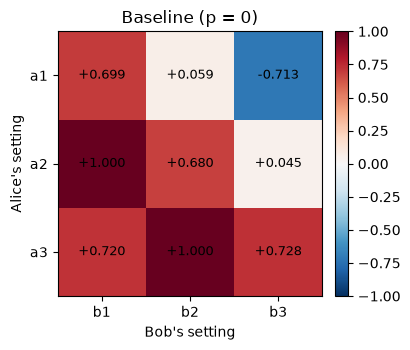

Figure 1: measured correlations E(a_i, b_j) without Eve; the CHSH pairs (a3,b1), (a3,b3), (a1,b1) are near +0.71 and (a1,b3) near -0.71, so S is close to 2*sqrt(2).

Full attack (p=1): S = 1.357 +/- 0.059, QBER = 0.2152, key length = 1984
pair   measured   predicted   (meas-pred)/sigma
(0,0)  +0.1752    +0.2357     -1.95
(0,1)  +0.0084    +0.0000     +0.26
(0,2)  -0.2703    -0.2357     -1.16
(1,0)  +0.4796    +0.5000     -0.75
(1,1)  +0.4648    +0.4714     -0.24
(1,2)  +0.1829    +0.1667     +0.52
(2,0)  +0.4572    +0.4714     -0.52
(2,1)  +0.6622    +0.6667     -0.19
(2,2)  +0.4544    +0.4714     -0.61


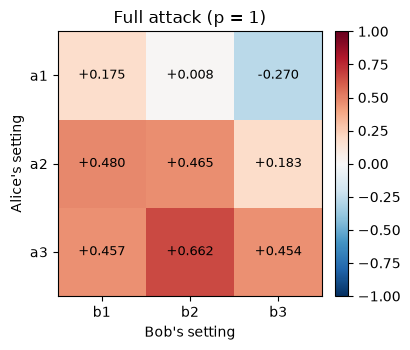

Figure 2: correlation table under a full intercept-resend attack; correlations shrink and S drops below 2.


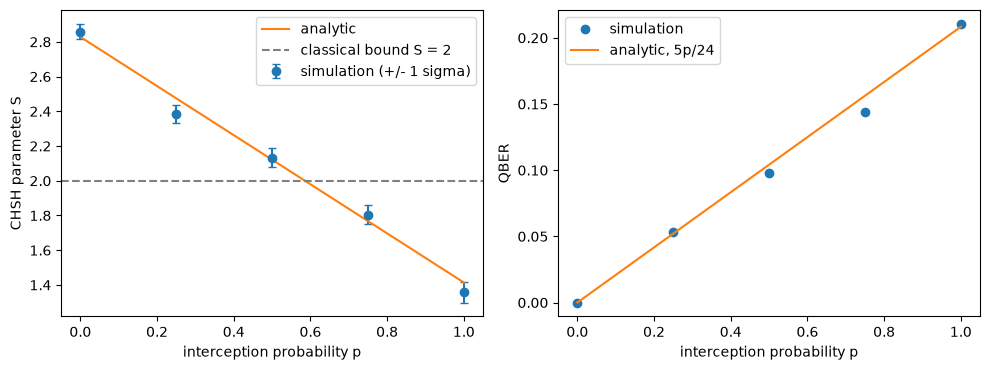

Figure 3: CHSH parameter S (left) and QBER (right) versus interception probability p for 9000 rounds per point. S falls linearly through the classical bound near p = 0.59; the QBER rises linearly, 5p/24.


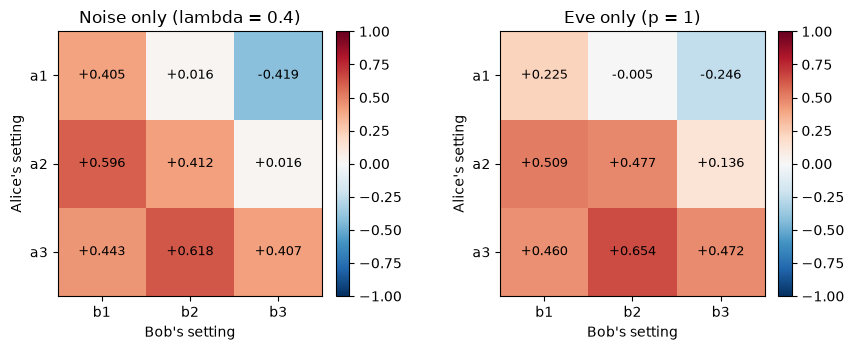

Figure 4: correlation tables for depolarizing noise (left, every entry scaled by 0.6) and a full attack (right, a different pattern).
noise only: S = 1.674, QBER = 0.1966, classifier -> depolarizing
Eve only  : S = 1.402, QBER = 0.2099, classifier -> eavesdropper
mixture (p=0.5, lambda=0.2) -> eavesdropper


In [41]:
# Participant Code: Task E91-X1
# Experiments for Section 9.
LAMBDA_NOISE = 0.4
PS = [0.0, 0.25, 0.5, 0.75, 1.0]

# 1. Baseline
base = run_e91(N_ROUNDS_DEMO, 0.0, SEED)
print(f"Baseline (p=0): S = {base['S']:.3f} +/- {base['S_std_error']:.3f}, "
      f"QBER = {base['qber']:.4f}, key length = {base['key_length']}")
ph.plot_correlation_table(base["correlations"], title="Baseline (p = 0)")
plt.tight_layout(); plt.show()
print("Figure 1: measured correlations E(a_i, b_j) without Eve; the CHSH pairs (a3,b1), (a3,b3), (a1,b1) "
      "are near +0.71 and (a1,b3) near -0.71, so S is close to 2*sqrt(2).")

# 2. Full attack
full = run_e91(N_ROUNDS_DEMO, 1.0, SEED)
print(f"\nFull attack (p=1): S = {full['S']:.3f} +/- {full['S_std_error']:.3f}, "
      f"QBER = {full['qber']:.4f}, key length = {full['key_length']}")
print("pair   measured   predicted   (meas-pred)/sigma")
for (i, j), e in full["correlations"].items():
    pred = predicted_correlation(ALICE_ANGLES[i], BOB_ANGLES[j], 1.0)
    sig = math.sqrt((1 - pred ** 2) / full["counts"][(i, j)])
    print(f"({i},{j})  {e:+.4f}    {pred:+.4f}     {(e - pred) / sig:+.2f}")
ph.plot_correlation_table(full["correlations"], title="Full attack (p = 1)")
plt.tight_layout(); plt.show()
print("Figure 2: correlation table under a full intercept-resend attack; correlations shrink and S drops below 2.")

# 3. Sweep
S_meas, S_err, Q_meas = [], [], []
for k, p in enumerate(PS):
    r = run_e91(N_ROUNDS_DEMO, p, SEED + k)
    S_meas.append(r["S"]); S_err.append(r["S_std_error"]); Q_meas.append(r["qber"])

def predicted_S(p, lam=0.0):
    E = lambda i, j: predicted_correlation(ALICE_ANGLES[i], BOB_ANGLES[j], p, lam)
    return abs(E(2, 0) + E(2, 2) + E(0, 0) - E(0, 2))

def predicted_qber(p, lam=0.0):
    return (1 - 0.5 * (predicted_correlation(ALICE_ANGLES[1], BOB_ANGLES[0], p, lam)
                       + predicted_correlation(ALICE_ANGLES[2], BOB_ANGLES[1], p, lam))) / 2

pg = np.linspace(0, 1, 101)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.errorbar(PS, S_meas, yerr=S_err, fmt="o", capsize=3, label="simulation (+/- 1 sigma)")
ax1.plot(pg, [predicted_S(p) for p in pg], label="analytic")
ax1.axhline(2, color="gray", ls="--", label="classical bound S = 2")
ax1.set_xlabel("interception probability p"); ax1.set_ylabel("CHSH parameter S"); ax1.legend()
ax2.plot(PS, Q_meas, "o", label="simulation")
ax2.plot(pg, [predicted_qber(p) for p in pg], label="analytic, 5p/24")
ax2.set_xlabel("interception probability p"); ax2.set_ylabel("QBER"); ax2.legend()
plt.tight_layout(); plt.show()
print("Figure 3: CHSH parameter S (left) and QBER (right) versus interception probability p for "
      f"{N_ROUNDS_DEMO} rounds per point. S falls linearly through the classical bound near p = 0.59; "
      "the QBER rises linearly, 5p/24.")

# 4. Stretch: noise versus Eve
noise_run = run_e91(30000, 0.0, SEED + 100, channel=transmission_channel(LAMBDA_NOISE))
eve_run = run_e91(30000, 1.0, SEED + 101)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
ph.plot_correlation_table(noise_run["correlations"], title=f"Noise only (lambda = {LAMBDA_NOISE})", ax=axes[0])
ph.plot_correlation_table(eve_run["correlations"], title="Eve only (p = 1)", ax=axes[1])
plt.tight_layout(); plt.show()
print("Figure 4: correlation tables for depolarizing noise (left, every entry scaled by 0.6) "
      "and a full attack (right, a different pattern).")
for name, r in (("noise only", noise_run), ("Eve only", eve_run)):
    print(f"{name:10s}: S = {r['S']:.3f}, QBER = {r['qber']:.4f}, "
          f"classifier -> {classify_disturbance(r['correlations'], r['counts'])}")
mix = run_e91(30000, 0.5, SEED + 102, channel=transmission_channel(0.2))
print("mixture (p=0.5, lambda=0.2) ->", classify_disturbance(mix["correlations"], mix["counts"]))

**Your answer (E91-Q1):**

An observed S above 2 (here S = 2.859 ± 0.044 without Eve, close to the Tsirelson value 2√2 ≈ 2.828) rules out every local hidden-variable model, so the measured pairs must have been entangled; an intercept-resend eavesdropper turns each pair into a classically correlated product state and pushes S down to at most about √2 for a full attack. This holds only under the assumptions of a Bell test: the settings are chosen randomly and independently of the source, the two stations cannot signal to each other, and all rounds are counted without post-selection. The CHSH value is a statement about the shared state, while the QBER measures the disagreement of the sifted key: in the noiseless case any Eve who measures in the wrong direction shows up as key errors, but the QBER alone does not say how much she knows once noise or device flaws are present. Neither number is a security proof. A real protocol still needs a finite-key bound on Eve's information, error correction, privacy amplification, an authenticated classical channel, and a treatment of device imperfections and side channels.

**Your answer (E91-Q2):**

**Derivation.** Take the angles a (Alice) and b (Bob). Without Eve the pair is |Φ⁺⟩ and E = cos(a − b). A depolarizing channel on Bob's qubit, ρ → (1−λ)ρ + λI/2, multiplies every correlation involving that qubit by (1−λ), so E = (1−λ)cos(a − b). If Eve intercepts after the channel and measures A(e) with result m, both qubits are left in the product state R_y(e)|m⟩ ⊗ R_y(e)|m⟩ (Alice's qubit collapses because the pair is perfectly correlated along e). For a product state E = ⟨A(a)⟩⟨A(b)⟩ = (−1)^m cos(a−e) · (−1)^m cos(e−b) = cos(a−e)cos(e−b). The noise factor (1−λ) still multiplies the whole result. Averaging over e ∈ {π/4, π/2, 3π/4} with cos x cos y = ½[cos(x−y) + cos(x+y)] gives ½cos(a−b) − ⅙cos(a+b), since the cos(a+b−2e) terms sum to −⅓cos(a+b) over the three angles. Mixing the two cases with probability p:

E(a,b) = (1−λ) [ (1−p) cos(a−b) + p ( ½ cos(a−b) − ⅙ cos(a+b) ) ].

For the CHSH settings this gives S(p, λ=0) = 2√2 − √2 p, and for the key pairs QBER = 5p/24.

**Comparison (9000 rounds, seed 2026).**

| | S measured | S predicted | deviation | QBER measured | QBER predicted | deviation |
|:--|:--|:--|:--|:--|:--|:--|
| p = 0 | 2.859 ± 0.044 | 2.828 | +0.7 σ | 0.0000 | 0 | exact |
| p = 1 | 1.357 ± 0.059 | 1.414 | −1.0 σ | 0.2152 | 0.2083 | +0.8 σ (σ ≈ 0.0091) |

The per-pair table printed in the experiment cell for p = 1 has all nine deviations between −1.95 σ and +0.52 σ. These are consistent with statistical fluctuations.

**Your answer (E91-Q3):**

With p = 0.2 and λ = 0 the correlations are linear in p, so S(p) = 2√2 − √2·p ≈ 2.546 and the drop from the ideal value is ΔS = √2·p ≈ 0.283. Each CHSH pair gets n/9 rounds, so σ_S = √(Σ_t (1 − E_t²)/(n/9)); with E ≈ 0.660 for the two (a₃,·) pairs and |E| ≈ 0.613 for the two (a₁,·) pairs, Σ_t (1 − E_t²) ≈ 2.38 and σ_S ≈ 4.63/√n. Requiring ΔS ≥ 5σ_S gives √n ≥ 5·4.63/0.283 ≈ 82, so n ≈ 6.7·10³ rounds (the ideal value 2√2 is assumed known, which is fair in a noiseless setting; if the comparison is against the classical bound S = 2 instead, S = 2.546 is 0.546 above it and about 1.8·10³ rounds are enough to show a violation, but that shows entanglement, not the absence of Eve). The QBER is far more sensitive in the noiseless case: it is exactly 0 without Eve, so a single disagreement in the key reveals interference. Eve causes a key error with probability 5p/24 ≈ 0.042 per key round, and key rounds are 2/9 of all rounds, so the expected number of errors is about 0.0093 n; one needs only n ≈ 110 rounds to expect one error, and a few hundred rounds to see several (probability of missing her below e⁻⁵ at about 540 rounds). The QBER therefore detects the attack with more than ten times fewer rounds than the CHSH test, but it is sensitive to any noise, whereas the Bell test would still certify entanglement in the presence of device imperfections.

**Your answer (E91-Q4):**

**Method.** Depolarizing noise multiplies all nine correlations by the same factor, whereas interception changes each pair by a different amount. I fit all nine estimates with the two-parameter model E_ij = u·c_ij + v·(r_ij − c_ij), where c_ij = cos(a_i − b_j) is the clean correlation, r_ij is the fully intercepted correlation from `predicted_correlation(…, p=1)`, u = 1−λ and v = (1−λ)p. The fit is weighted least squares with weights n_ij/(1 − E_ij²) (a floor of 1/n on the variance avoids division by zero when |E| = 1), and the standard errors of u and v come from the inverse weighted normal matrix. Equivalently, interception adds a −(1−λ)p/6 · cos(a+b) term that noise cannot produce. The label is "eavesdropper" if v exceeds 5 standard errors, "depolarizing" if v is within 5 standard errors of 0 while 1−u exceeds 5 of its standard errors, and "inconclusive" otherwise.

**Results (30 000 rounds each).** λ = 0.4 without Eve: S = 1.674, QBER = 0.197, classified "depolarizing". p = 1 without noise: S = 1.402, QBER = 0.210, classified "eavesdropper". A mixture (p = 0.5, λ = 0.2) was classified "eavesdropper", as required. The S and QBER values of the first two datasets are almost the same, so neither number alone could tell them apart; only the pattern across the nine pairs does.

**Limits.** Classification fails when the disturbance is too small for v to reach 5 standard errors, or when the noise level is so high that all correlations are close to 0. It is impossible in principle for an eavesdropper who chooses her direction uniformly from the whole x–z plane: averaging cos(a−e)cos(e−b) over all e gives ½cos(a−b), so the cos(a+b) term vanishes and the attack looks exactly like depolarizing noise with factor (1 − p/2). Then the nine-pair pattern carries no signature. An additional measurement helps: measuring along the y axis as well (or calibrating the line's noise λ separately) provides extra constraints, because Eve's x–z measurements disturb y correlations differently from isotropic depolarizing noise.

## 10. Expected deliverables

Submit this notebook with:

1. Working implementations of `create_bell_pair`, `add_measurement`, `add_intercept_resend`, `build_round_circuit`, `correlation`, `chsh_value`, `chsh_standard_error`, `sift_key`, `qber`, `predicted_correlation`, `run_e91` and `classify_disturbance`, with the exact names and parameter lists given above.
2. The experiments of Section 9, including the requested figures with captions.
3. Written answers to E91-Q1, E91-Q2, E91-Q3 and E91-Q4.

The notebook must execute from top to bottom in a fresh kernel within 15 minutes on a standard laptop.

## 11. Published scoring rubric

| Criterion | Points | Assessment |
|:--|--:|:--|
| E91-C1 Bell-state preparation (T1) | 8 | automatic |
| E91-C2 Measurement along a direction (T2) | 10 | automatic |
| E91-C3 Intercept-resend attack (T3) | 10 | automatic |
| E91-C4 Round circuit, channel and bit layout (T4) | 8 | automatic |
| E91-C5 Correlations, CHSH value and its standard error (T5) | 12 | automatic |
| E91-C6 Sifting and QBER (T6) | 10 | automatic |
| E91-C7 Analytic predictions (T7) | 8 | automatic |
| E91-C8 End-to-end protocol with hidden parameters and seeds (T8) | 16 | automatic |
| E91-C9 Stretch: interception versus noise (T9) | 8 | automatic |
| E91-C10 Scientific interpretation (Q1 to Q4, experiments and figures) | 10 | manual, structured review form |
| **Total** | **100** | |

**Rules that apply to every challenge**

* Automatic criteria are evaluated by re-executing your notebook in a clean, isolated environment with a fresh random seed. Saved outputs in the submitted file are ignored.
* Statistical checks use tolerances of at least five standard errors, so a correct implementation passes with overwhelming probability for any seed.
* Partial credit is awarded per hidden test case within each criterion. If a cell raises an error, execution continues, and only the criteria that depend on the failing function are affected.
* Modifying, deleting, duplicating or reordering a protected cell, or altering a required function signature, is an integrity violation. Formatting-only changes (whitespace and comments) are recorded but not penalised. A substantive change to protected code holds the challenge score for judge review; the default outcome is zero points for the affected challenge, and deliberate circumvention of the grading system leads to disqualification. An altered function signature gives zero points for the criteria that use that function.
* Hardcoding results, reading hidden test data, or bypassing the provided simulation helpers is not permitted.
* You may use AI assistants to help you understand concepts and theory, but the code you submit must be written by your team, not produced by AI tools.

## 12. Submission instructions

1. Restart the kernel and run all cells (in Jupyter: *Kernel*, then *Restart Kernel and Run All Cells*). Check that no cell fails unexpectedly and that the run completes within the time limit.
2. Save the notebook without renaming it: the file name must remain `01_e91_quantum_key_distribution.ipynb`.
3. Place it in your team folder together with the other two notebooks and submit the folder as described in `README.md` before the deadline.

## 13. Scientific references

1. A. K. Ekert, "Quantum cryptography based on Bell's theorem," *Physical Review Letters* 67, 661 (1991). DOI: 10.1103/PhysRevLett.67.661
2. J. S. Bell, "On the Einstein Podolsky Rosen paradox," *Physics Physique Fizika* 1, 195 (1964). DOI: 10.1103/PhysicsPhysiqueFizika.1.195
3. J. F. Clauser, M. A. Horne, A. Shimony and R. A. Holt, "Proposed experiment to test local hidden-variable theories," *Physical Review Letters* 23, 880 (1969). DOI: 10.1103/PhysRevLett.23.880
4. B. S. Cirel'son, "Quantum generalizations of Bell's inequality," *Letters in Mathematical Physics* 4, 93 (1980). DOI: 10.1007/BF00417500
5. A. Acin, N. Brunner, N. Gisin, S. Massar, S. Pironio and V. Scarani, "Device-independent security of quantum cryptography against collective attacks," *Physical Review Letters* 98, 230501 (2007). DOI: 10.1103/PhysRevLett.98.230501
6. V. Scarani, H. Bechmann-Pasquinucci, N. J. Cerf, M. Dusek, N. Lutkenhaus and M. Peev, "The security of practical quantum key distribution," *Reviews of Modern Physics* 81, 1301 (2009). DOI: 10.1103/RevModPhys.81.1301
7. M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, 10th anniversary edition, Cambridge University Press (2010), Sections 2.6 and 12.6.
8. Qiskit documentation: https://quantum.cloud.ibm.com/docs/en/api/qiskit
9. Qiskit Aer documentation: https://qiskit.github.io/qiskit-aer/